# Benchmark - End-to-End Consensus Pipeline & Evaluation

- **Part A (Run Analysis):** Standardized 4-stage ViroConstrictor-style pipeline (`AdapterRemover` $\rightarrow$ Primer Removal (`no_trim`, `ampligone`, `bitvector_longest`, `sassy`, `semiglobal`) $\rightarrow$ `minimap2` $\rightarrow$ `TrueConsense`), read-level trim diagnostics, and CTE-style consensus evaluation against the ECDC ESIB EQA Gold (`high_cov`, 10% ambiguity margin) and Silver (`low_cov`, 20% ambiguity margin) truth alignments.
- **Part B (Results & Visualization):** Pooled accuracy tables (Gold and Silver standards), error analysis (`primer_site` vs `amplicon_overlap` vs `amplicon_unique`), per-sample error deltas against `no_trim`, and site-level method disagreements.

**Caching:** Every step checks `if output_path.is_file():` first. If the output file already exists on disk, the step is skipped. Delete the output file(s) to re-run.

## Part A, Run Consensus Pipeline & Evaluation

In [26]:
from dataclasses import dataclass
import gzip
import json
import os
from pathlib import Path
import re
import shutil
import subprocess
import sys
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import primer_matchers as pm

MANUAL_DIR = ROOT / "manual_test"
DATASET_DIR = MANUAL_DIR / "datasets"
PROCESSED_DIR = MANUAL_DIR / "processed"
RESULTS_DIR = PROCESSED_DIR / "benchmark2"
PIPELINE_DIR = RESULTS_DIR / "pipeline"
RAW_DEPTH_DIR = RESULTS_DIR / "raw_depth"
PIPELINE_DIR.mkdir(parents=True, exist_ok=True)

REFERENCE_ID = "MN908947.3"
REFERENCE_FASTA = MANUAL_DIR / "MN908947.fasta"
REFERENCE_GFF = MANUAL_DIR / "MN908947.gff"
YEARS = ("2023", "2024", "2025", "2026")
VC_MIN_COVERAGE = 30
PRIMER_METHODS = ("no_trim", "ampligone", "bitvector_longest", "sassy", "semiglobal")
FULL_RUN_METHODS = PRIMER_METHODS
TRUTH_STANDARDS = ("gold", "silver")
PRIMARY_STANDARD = "gold"
UNSCORABLE = {"EQA_2023_22", "EQA_2024_12"}

ENVS = {"main": "ampligone_thesis", "vc": "ampligone_thesis_vc"}
ENV_ROOT = Path(sys.prefix).parent


def run_cmd(cmd, env_key: str = "main", check: bool = True, **kwargs) -> subprocess.CompletedProcess:
    env_dir = ENV_ROOT / ENVS[env_key] / "bin"
    env = os.environ.copy()
    env["PATH"] = f"{env_dir}:{env.get('PATH', '')}"
    return subprocess.run(cmd, env=env, check=check, text=True, capture_output=True, **kwargs)


def read_fasta(path: Path) -> dict[str, str]:
    records: dict[str, list[str]] = {}
    header = None
    with path.open() as handle:
        for raw in handle:
            line = raw.strip()
            if not line:
                continue
            if line.startswith(">"):
                header = line[1:].split()[0]
                records[header] = []
            else:
                records[header].append(line.upper())
    return {name: "".join(parts) for name, parts in records.items()}


REF_SEQ = read_fasta(REFERENCE_FASTA)[REFERENCE_ID]
REF_LEN = len(REF_SEQ)

COHORTS = {}
SAMPLES = {}
for year in YEARS:
    stem = f"ESIB_EQA_{year}"
    reads = sorted((DATASET_DIR / year).glob(f"{stem}*.fastq.gz"))
    COHORTS[year] = {
        "year": year,
        "reads": reads,
        "primer_bed": DATASET_DIR / f"{stem}.SARS1.primers.bed",
        "primer_fasta": DATASET_DIR / f"{stem}.SARS1.primers.fasta",
        "truth_alignments": {
            "gold": DATASET_DIR / f"{stem}.SARS1.gold_standard.high_cov.alignment.fasta",
            "silver": DATASET_DIR / f"{stem}.SARS1.gold_standard.low_cov.alignment.fasta",
        },
    }
    for fq in reads:
        number = re.search(r"(\d\d)\.fastq\.gz$", fq.name).group(1)
        sample = f"EQA_{year}_{number}"
        if sample in UNSCORABLE:
            continue
        truth_id = f"ESIB_EQA_{year}.SARS1.{number}" if year == "2023" else f"ESIB_EQA_{year}_SARS1_{number}"
        SAMPLES[sample] = {
            "sample": sample,
            "year": year,
            "number": number,
            "fastq": fq,
            "truth_id": truth_id,
            "primer_bed": COHORTS[year]["primer_bed"],
            "primer_fasta": COHORTS[year]["primer_fasta"],
        }

FULL_RUN_SAMPLES = sorted(SAMPLES)
print(f"Loaded {len(FULL_RUN_SAMPLES)} scored ECDC ESIB EQA samples.")

Loaded 70 scored ECDC ESIB EQA samples.


In [27]:
# Load Primer Schemes and Truth Genomes (Gold = high_cov 10%, Silver = low_cov 20%)
# Primer names: <scheme>_<amplicon>[_<alt>]_LEFT|RIGHT[_<alt>], e.g. ncov-2019_10_LEFT_alt1
AMPLICON_RE = re.compile(
    r"^(?P<scheme>.+?)_(?P<amplicon>\d+)"
    r"(?:_(?P<alt_before>[^_]+))?_(?P<side>LEFT|RIGHT)"
    r"(?:_(?P<alt_after>[^_]+))?$"
)
STRATUM_ORDER = ("primer_site", "amplicon_overlap", "amplicon_unique", "outside_scheme")
DNA_BASES = {"A", "C", "G", "T"}
IUPAC_MAP = {
    "A": frozenset("A"), "C": frozenset("C"), "G": frozenset("G"), "T": frozenset("T"),
    "R": frozenset("AG"), "Y": frozenset("CT"), "S": frozenset("GC"), "W": frozenset("AT"),
    "K": frozenset("GT"), "M": frozenset("AC"), "B": frozenset("CGT"), "D": frozenset("AGT"),
    "H": frozenset("ACT"), "V": frozenset("ACG"), "N": frozenset("ACGT"),
}
AMBIGUOUS_BASES = set(IUPAC_MAP) - DNA_BASES - {"N"}


@dataclass(frozen=True)
class PrimerScheme:
    year: str
    primers: pd.DataFrame
    amplicons: pd.DataFrame
    strata: np.ndarray


def load_primer_scheme(year: str) -> PrimerScheme:
    bed_path = COHORTS[year]["primer_bed"]
    fasta_records = read_fasta(COHORTS[year]["primer_fasta"])
    rows = []
    with bed_path.open() as handle:
        for line in handle:
            if not line.strip() or line.startswith("#"):
                continue
            fields = line.rstrip("\n").split("\t")
            chrom, start, end, name, pool, strand = fields[:6]
            seq = (fields[6] if len(fields) > 6 else fasta_records[name]).upper()
            parsed = AMPLICON_RE.match(name)
            if parsed is None:
                raise ValueError(f"Primer name does not match the expected scheme: {name!r}")
            rows.append({
                "chrom": chrom, "start": int(start), "end": int(end), "name": name,
                "pool": str(pool), "strand": strand, "sequence": seq,
                "length": int(end) - int(start), "amplicon": int(parsed.group("amplicon")),
                "side": parsed.group("side"), "alt": parsed.group("alt_before") or parsed.group("alt_after") or "",
            })
    primers = pd.DataFrame(rows).sort_values(["amplicon", "side", "start", "name"]).reset_index(drop=True)
    amplicon_rows = []
    for amp_id, group in primers.groupby("amplicon"):
        left = group[group["side"] == "LEFT"]
        right = group[group["side"] == "RIGHT"]
        amplicon_rows.append({
            "amplicon": int(amp_id), "pool": group["pool"].iloc[0],
            "outer_start": int(left["start"].min()), "inner_start": int(left["end"].max()),
            "inner_end": int(right["start"].min()), "outer_end": int(right["end"].max()),
        })
    amplicons = pd.DataFrame(amplicon_rows).sort_values("amplicon").reset_index(drop=True)
    primer_mask = np.zeros(REF_LEN, dtype=bool)
    for row in primers.itertuples():
        primer_mask[row.start:row.end] = True
    amplicon_depth = np.zeros(REF_LEN, dtype=np.int16)
    for row in amplicons.itertuples():
        amplicon_depth[row.outer_start:row.outer_end] += 1
    strata = np.full(REF_LEN, "outside_scheme", dtype=object)
    strata[(amplicon_depth == 1) & ~primer_mask] = "amplicon_unique"
    strata[(amplicon_depth >= 2) & ~primer_mask] = "amplicon_overlap"
    strata[primer_mask] = "primer_site"
    return PrimerScheme(year=year, primers=primers, amplicons=amplicons, strata=strata)


SCHEMES = {year: load_primer_scheme(year) for year in YEARS}


@dataclass(frozen=True)
class TruthGenome:
    sample: str
    year: str
    standard: str
    truth_id: str
    ref_aligned: str
    truth_aligned: str
    ungapped_seq: str
    ref_pos: np.ndarray
    ref_bases: np.ndarray
    truth_bases: np.ndarray
    insertion_anchors: dict[int, str]
    deletion_runs: list[tuple[int, int]]
    defined_mask: np.ndarray
    scorable_mask: np.ndarray
    strata: np.ndarray


def build_truth_genome(sample: str, standard: str, alignments: dict[str, dict[str, str]]) -> TruthGenome:
    meta = SAMPLES[sample]
    year = meta["year"]
    aln = alignments[year]
    ref_aln = aln[REFERENCE_ID]
    truth_aln = aln[meta["truth_id"]]
    ref_positions, ref_bases, truth_bases = [], [], []
    insertion_buffers: dict[int, list[str]] = {}
    ref_idx = 0
    for r_ch, t_ch in zip(ref_aln, truth_aln):
        if r_ch == "-":
            if t_ch not in ("-", "N"):
                insertion_buffers.setdefault(max(ref_idx - 1, 0), []).append(t_ch)
        else:
            ref_positions.append(ref_idx)
            ref_bases.append(r_ch)
            truth_bases.append(t_ch)
            ref_idx += 1
    ref_pos = np.array(ref_positions, dtype=np.int32)
    ref_arr = np.array(ref_bases, dtype="U1")
    truth_arr = np.array(truth_bases, dtype="U1")
    defined = (truth_arr != "N") & (SCHEMES[year].strata != "outside_scheme")
    scorable = defined.copy()
    for anchor in list(insertion_buffers):
        if not scorable[anchor]:
            insertion_buffers.pop(anchor, None)
    insertions = {pos: "".join(chars) for pos, chars in insertion_buffers.items()}
    del_runs = []
    in_del, start = False, 0
    for idx, is_del in enumerate((truth_arr == "-") & scorable):
        if is_del and not in_del:
            in_del, start = True, idx
        elif not is_del and in_del:
            del_runs.append((start, idx - start))
            in_del = False
    if in_del:
        del_runs.append((start, len(truth_arr) - start))
    ungapped = "".join(ch for ch in truth_aln if ch != "-")
    return TruthGenome(
        sample=sample, year=year, standard=standard, truth_id=meta["truth_id"],
        ref_aligned=ref_aln, truth_aligned=truth_aln, ungapped_seq=ungapped,
        ref_pos=ref_pos, ref_bases=ref_arr, truth_bases=truth_arr,
        insertion_anchors=insertions, deletion_runs=del_runs,
        defined_mask=defined, scorable_mask=scorable, strata=SCHEMES[year].strata,
    )


ALIGNMENTS = {
    standard: {year: read_fasta(COHORTS[year]["truth_alignments"][standard]) for year in YEARS}
    for standard in TRUTH_STANDARDS
}
TRUTH_GENOMES = {
    (standard, sample): build_truth_genome(sample, standard, ALIGNMENTS[standard])
    for standard in TRUTH_STANDARDS for sample in SAMPLES
}
print(f"Built {len(TRUTH_GENOMES)} 'Truth' comparator genome objects across {len(SAMPLES)} samples and {TRUTH_STANDARDS} standards.")

Built 140 'Truth' comparator genome objects across 70 samples and ('gold', 'silver') standards.


In [28]:
# 5. Standardized 4-Stage Pipeline Runners

def pipeline_paths(sample: str, method: str, workdir: Path = PIPELINE_DIR, min_coverage: int = VC_MIN_COVERAGE) -> dict[str, Path]:
    shared = workdir / "shared" / sample
    own = workdir / method / sample
    tag = f"05.cov{min_coverage}"
    return {
        "shared_dir": shared,
        "method_dir": own,
        "adapters_fq": shared / "01.adapters_removed.fastq",
        "adapters_calls": shared / "01.adapter_calls.tsv",
        "primers_fq": own / "03.primers_removed.adapter_only.fastq",
        "removed_bed": own / "03.removed_primers.bed",
        "primers_calls": own / "03.primer_calls.tsv",
        "bam": own / "04.aligned.bam",
        "bai": own / "04.aligned.bam.bai",
        "consensus": own / f"{tag}.consensus.fasta",
        "vcf": own / f"{tag}.variants.vcf",
        "coverage": own / f"{tag}.coverage.tsv",
        "gff": own / f"{tag}.features.gff",
    }


def run_trimmer(method: str, fq_in: Path, fq_out: Path, *, calls_out: Path | None = None,
                primer_fasta: Path | None = None, workers: int = 1) -> dict:
    trimmer = pm.create_trimmer(method, primer_fasta)
    counts = pm.trim_fastq(trimmer, fq_in, fq_out, calls_path=calls_out, workers=workers)
    reads_out = bases_out = 0
    for record in pm.read_fastq(fq_out):
        reads_out += 1
        bases_out += len(record.sequence)
    return {
        "method": method, "reads": counts["total_reads"], "output_reads": reads_out,
        "bases_in": bases_out + counts["bases_removed"], "bases_out": bases_out,
        "bases_removed": counts["bases_removed"], "wall_seconds": counts["elapsed"],
    }


def run_shared_adapter_removal(sample: str, workers: int = 8) -> Path:
    meta = SAMPLES[sample]
    paths = pipeline_paths(sample, "no_trim")
    paths["shared_dir"].mkdir(parents=True, exist_ok=True)
    if paths["adapters_fq"].is_file() and paths["adapters_fq"].stat().st_size > 0:
        return paths["adapters_fq"]
    run_trimmer("adapters", meta["fastq"], paths["adapters_fq"], calls_out=paths["adapters_calls"], workers=workers)
    return paths["adapters_fq"]


def run_primer_trim_stage(sample: str, method: str, threads: int = 8) -> Path:
    meta = SAMPLES[sample]
    paths = pipeline_paths(sample, method)
    paths["method_dir"].mkdir(parents=True, exist_ok=True)
    fq_out = paths["primers_fq"]
    if fq_out.is_file() and fq_out.stat().st_size > 0:
        return fq_out

    fq_in = run_shared_adapter_removal(sample, workers=threads)
    if method == "no_trim":
        if fq_out.exists() or fq_out.is_symlink():
            fq_out.unlink()
        fq_out.symlink_to(fq_in)
    elif method == "ampligone":
        cmd = [
            "AmpliGone", "-i", str(fq_in), "-ref", str(REFERENCE_FASTA), "-pr", str(meta["primer_bed"]),
            "-o", str(fq_out), "-at", "end-to-end", "--error-rate", "0.1",
            "--export-primers", str(paths["removed_bed"]), "-ap", "map-ont",
            "-as", "match=4", "mismatch=4", "gap_o1=8", "gap_e1=2", "gap_o2=24", "gap_e2=0",
            "--virtual-primers", "-to", "-t", str(threads),
        ]
        run_cmd(cmd, env_key="main")
    else:
        run_trimmer(
            method, fq_in, fq_out, primer_fasta=meta["primer_fasta"],
            calls_out=paths["primers_calls"], workers=threads,
        )
    return fq_out


def run_align_and_consensus(sample: str, method: str, threads: int = 8, min_coverage: int = VC_MIN_COVERAGE) -> dict[str, Path]:
    paths = pipeline_paths(sample, method, PIPELINE_DIR, min_coverage)
    paths["consensus"].parent.mkdir(parents=True, exist_ok=True)
    if paths["consensus"].is_file() and paths["consensus"].stat().st_size > 0:
        return paths

    if not (paths["bam"].is_file() and paths["bai"].is_file()):
        fq_trimmed = run_primer_trim_stage(sample, method, threads=threads)
        mm2_threads = max(threads - 1, 1)
        cmd = (
            f"minimap2 -ax map-ont --secondary=no -r 2000,20k -E2,0 -O8,24 -t {mm2_threads} "
            f"{REFERENCE_FASTA} {fq_trimmed} "
            f"| samtools view -@ {threads} -F 256 -F 512 -F 4 -F 2048 -uS "
            f"| samtools sort -@ {threads} -o {paths['bam']} "
            f"&& samtools index {paths['bam']}"
        )
        run_cmd(["bash", "-lc", cmd], env_key="main")

    tc_cmd = [
        "TrueConsense",
        "--input", str(paths["bam"]),
        "--reference", str(REFERENCE_FASTA),
        "--features", str(REFERENCE_GFF),
        "--coverage-level", str(min_coverage),
        "--samplename", f"{sample}.{method}.cov{min_coverage}",
        "--output", str(paths["consensus"]),
        "--variants", str(paths["vcf"]),
        "--output-gff", str(paths["gff"]),
        "--depth-of-coverage", str(paths["coverage"]),
        "--threads", str(threads),
    ]
    run_cmd(tc_cmd, env_key="vc")
    return paths


# Skips any run whose consensus.fasta already exists on disk
for sample in FULL_RUN_SAMPLES:
    for method in FULL_RUN_METHODS:
        run_align_and_consensus(sample, method, threads=8, min_coverage=VC_MIN_COVERAGE)
print("All 70 samples x 5 methods pipeline runs verified on disk.")


All 70 samples x 5 methods pipeline runs verified on disk.


In [29]:
# 7b. Read-Level Trim Diagnostics
TRIM_DIAG_CSV = RESULTS_DIR / "attribution" / "trim_diagnostics.csv"

if TRIM_DIAG_CSV.is_file():
    print(f"Skipping trim diagnostics computation (already exists: {TRIM_DIAG_CSV})")
else:
    TRIM_DIAG_CSV.parent.mkdir(parents=True, exist_ok=True)
    diag_rows = []
    for sample in FULL_RUN_SAMPLES:
        for method in ("bitvector_longest", "sassy", "semiglobal"):
            dec_path = pipeline_paths(sample, method)["primers_calls"]
            df = pd.read_csv(dec_path, sep="\t")
            removed = df["original_length"] - (df["retained_end"] - df["retained_start"])
            left_cut = df["retained_start"]
            right_cut = df["original_length"] - df["retained_end"]
            same_primer = (
                df["left_name"].notna()
                & df["right_name"].notna()
                & (df["left_name"] == df["right_name"])
            )
            diag_rows.append({
                "method": method,
                "sample": sample,
                "reads": len(df),
                "mean_bases_removed": float(removed.mean()),
                "left_cut_over_60": float((left_cut > 60).mean()),
                "right_cut_over_60": float((right_cut > 60).mean()),
                "high_cost_share": float(((df["left_cost"] >= 2) | (df["right_cost"] >= 2)).mean())
                if "left_cost" in df.columns else np.nan,
                "same_primer_both_ends": float(same_primer.mean()),
                "no_left_match": float(df["left_name"].isna().mean()),
                "no_right_match": float(df["right_name"].isna().mean()),
            })
    pd.DataFrame(diag_rows).to_csv(TRIM_DIAG_CSV, index=False)
    print(f"Wrote {TRIM_DIAG_CSV}")

Skipping trim diagnostics computation (already exists: /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/attribution/trim_diagnostics.csv)


In [30]:
# 8 & 9. Consensus Evaluation Engine (CTE-style with MAFFT --keeplength)
POSITION_ERROR_CLASSES = ("snp_missed_as_ref", "false_snp", "snp_wrong_base", "false_ambiguous_ref", "false_ambiguous_snp")
EVENT_ERROR_CLASSES = ("deletion_missed_retained", "false_deletion", "deletion_frame_mismatch", "insertion_missed", "false_insertion", "insertion_sequence_mismatch")
ERROR_CLASSES = POSITION_ERROR_CLASSES + EVENT_ERROR_CLASSES
MASKED_POSITION_CLASSES = ("masked_ref", "masked_snp", "masked_deletion", "masked_insertion_anchor")
DELETED_POSITION_CLASSES = ("correct_deleted_base", "false_deleted_base", "shifted_deleted_base")
AMBIGUOUS_CLASSES = ("ambiguous_snp_compatible", "false_ambiguous_ref", "false_ambiguous_snp")
SCORED_POSITION_CLASSES = (
    "correct_ref", "correct_snp", "correct_insertion", "truth_ambiguous_matched",
    *DELETED_POSITION_CLASSES, *POSITION_ERROR_CLASSES, "ambiguous_snp_compatible", *MASKED_POSITION_CLASSES,
)
INDEL_TOLERANCE = 5


def read_consensus(path: Path) -> str:
    records = read_fasta(path)
    return next(iter(records.values()))


def mafft_Coordinate_projection(consensus_seq: str) -> tuple[np.ndarray, dict[int, str]]:
    with tempfile.TemporaryDirectory() as tmp:
        tmp_path = Path(tmp)
        query_fa = tmp_path / "query.fasta"
        query_fa.write_text(f">consensus\n{consensus_seq}\n")
        keep = run_cmd(["mafft", "--quiet", "--keeplength", "--addfragments", str(query_fa), str(REFERENCE_FASTA)], env_key="vc")
        keep_records = {}
        header = None
        for line in keep.stdout.splitlines():
            if line.startswith(">"):
                header = line[1:].split()[0]
                keep_records[header] = []
            elif header:
                keep_records[header].append(line.strip().upper())
        cons_keep = "".join(keep_records["consensus"])
        cons_arr = np.array(list(cons_keep), dtype="U1")

        full = run_cmd(["mafft", "--quiet", "--addfragments", str(query_fa), str(REFERENCE_FASTA)], env_key="vc")
        full_records = {}
        header = None
        for line in full.stdout.splitlines():
            if line.startswith(">"):
                header = line[1:].split()[0]
                full_records[header] = []
            elif header:
                full_records[header].append(line.strip().upper())
        ref_full = "".join(full_records[REFERENCE_ID])
        cons_full = "".join(full_records["consensus"])
        ins_buffers: dict[int, list[str]] = {}
        ref_idx = 0
        for r_ch, c_ch in zip(ref_full, cons_full):
            if r_ch == "-":
                if c_ch not in ("-", "N"):
                    ins_buffers.setdefault(max(ref_idx - 1, 0), []).append(c_ch)
            else:
                ref_idx += 1
        insertions = {pos: "".join(chars) for pos, chars in ins_buffers.items()}
    return cons_arr, insertions


def prepare_consensus(consensus_seq: str) -> dict:
    cons_arr, insertions = mafft_Coordinate_projection(consensus_seq)
    del_runs = []
    in_del, start = False, 0
    for idx, ch in enumerate(cons_arr):
        if ch == "-" and not in_del:
            in_del, start = True, idx
        elif ch != "-" and in_del:
            del_runs.append((start, idx - start))
            in_del = False
    if in_del:
        del_runs.append((start, len(cons_arr) - start))
    return {"cons_bases": cons_arr, "insertions": insertions, "deletion_runs": del_runs}


def evaluate_consensus(consensus_seq: str, truth: TruthGenome, prepared: dict | None = None) -> dict:
    if prepared is None:
        prepared = prepare_consensus(consensus_seq)
    cons_arr = prepared["cons_bases"]
    cons_ins = {pos: seq for pos, seq in prepared["insertions"].items() if truth.scorable_mask[pos]}
    cons_dels = [(s, length) for s, length in prepared["deletion_runs"] if truth.scorable_mask[s:s + length].all()]

    outcomes = np.full(REF_LEN, "unscored", dtype=object)
    events = []

    matched_truth_dels, matched_cons_dels = set(), set()
    exact_del_positions, shifted_del_positions = set(), set()
    for t_idx, (t_start, t_len) in enumerate(truth.deletion_runs):
        best_c = None
        for c_idx, (c_start, c_len) in enumerate(cons_dels):
            if c_idx in matched_cons_dels:
                continue
            if abs(c_start - t_start) <= INDEL_TOLERANCE:
                best_c = c_idx
                break
        if best_c is not None:
            matched_truth_dels.add(t_idx)
            matched_cons_dels.add(best_c)
            c_start, c_len = cons_dels[best_c]
            if (c_start, c_len) == (t_start, t_len):
                exact_del_positions.update(range(c_start, c_start + c_len))
                events.append(("correct_deletion_event", t_start, f"{t_len}bp"))
            else:
                shifted_del_positions.update(range(c_start, c_start + c_len))
                events.append(("deletion_frame_mismatch", t_start, f"truth={t_start}:{t_len},cons={c_start}:{c_len}"))
        else:
            slice_calls = cons_arr[t_start:t_start + t_len]
            if np.all(slice_calls == "N"):
                events.append(("masked_deletion_event", t_start, f"{t_len}bp"))
            else:
                events.append(("deletion_missed_retained", t_start, f"{t_len}bp"))

    for c_idx, (c_start, c_len) in enumerate(cons_dels):
        if c_idx not in matched_cons_dels:
            events.append(("false_deletion", c_start, f"{c_len}bp"))

    matched_truth_ins, matched_cons_ins = set(), set()
    correct_ins_anchors = set()
    for t_pos, t_seq in truth.insertion_anchors.items():
        best_c = None
        for c_pos, c_seq in cons_ins.items():
            if c_pos in matched_cons_ins:
                continue
            if abs(c_pos - t_pos) <= INDEL_TOLERANCE:
                best_c = c_pos
                break
        if best_c is not None:
            matched_truth_ins.add(t_pos)
            matched_cons_ins.add(best_c)
            if cons_ins[best_c] == t_seq:
                correct_ins_anchors.add(t_pos)
                events.append(("correct_insertion_event", t_pos, t_seq))
            else:
                events.append(("insertion_sequence_mismatch", t_pos, f"truth={t_seq},cons={cons_ins[best_c]}"))
        else:
            if cons_arr[t_pos] == "N":
                outcomes[t_pos] = "masked_insertion_anchor"
            else:
                events.append(("insertion_missed", t_pos, t_seq))

    for c_pos, c_seq in cons_ins.items():
        if c_pos not in matched_cons_ins:
            events.append(("false_insertion", c_pos, c_seq))

    for pos in np.flatnonzero(truth.scorable_mask):
        if outcomes[pos] == "masked_insertion_anchor":
            continue
        r_base = truth.ref_bases[pos]
        t_base = truth.truth_bases[pos]
        c_base = cons_arr[pos]

        if c_base == "-":
            if pos in exact_del_positions:
                outcomes[pos] = "correct_deleted_base"
            elif pos in shifted_del_positions:
                outcomes[pos] = "shifted_deleted_base"
            else:
                outcomes[pos] = "false_deleted_base"
            continue

        if t_base == "-":
            outcomes[pos] = "masked_deletion" if c_base == "N" else "correct_ref"
            continue

        if c_base == "N":
            outcomes[pos] = "masked_ref" if t_base == r_base else "masked_snp"
            continue

        if t_base in AMBIGUOUS_BASES:
            t_set = IUPAC_MAP[t_base]
            c_set = IUPAC_MAP.get(c_base, frozenset())
            if c_set and c_set.issubset(t_set):
                outcomes[pos] = "truth_ambiguous_matched"
            elif c_base == r_base:
                outcomes[pos] = "snp_missed_as_ref"
            else:
                outcomes[pos] = "snp_wrong_base"
            continue

        if c_base in AMBIGUOUS_BASES:
            c_set = IUPAC_MAP[c_base]
            if t_base == r_base:
                outcomes[pos] = "false_ambiguous_ref"
            elif t_base in c_set:
                outcomes[pos] = "ambiguous_snp_compatible"
            else:
                outcomes[pos] = "false_ambiguous_snp"
            continue

        if t_base == r_base:
            if c_base == r_base:
                outcomes[pos] = "correct_ref" if pos not in correct_ins_anchors else "correct_insertion"
            else:
                outcomes[pos] = "false_snp"
        else:
            if c_base == t_base:
                outcomes[pos] = "correct_snp" if pos not in correct_ins_anchors else "correct_insertion"
            elif c_base == r_base:
                outcomes[pos] = "snp_missed_as_ref"
            else:
                outcomes[pos] = "snp_wrong_base"

    return {"outcome": outcomes, "events": events}


def summarize(counts_df: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    piv = counts_df.pivot_table(index=group_cols, columns="class", values="count", aggfunc="sum", fill_value=0)
    for col in (*SCORED_POSITION_CLASSES, *EVENT_ERROR_CLASSES, "truth_snps", "truth_deletions", "truth_insertion_bases"):
        if col not in piv.columns:
            piv[col] = 0
    scored_pos = piv[list(SCORED_POSITION_CLASSES)].sum(axis=1)
    pos_errors = piv[list(POSITION_ERROR_CLASSES)].sum(axis=1)
    indel_errors = piv[list(EVENT_ERROR_CLASSES)].sum(axis=1)
    masked_pos = piv[list(MASKED_POSITION_CLASSES)].sum(axis=1)
    deleted_bases = piv[list(DELETED_POSITION_CLASSES)].sum(axis=1)
    ambig_calls = piv[list(AMBIGUOUS_CLASSES)].sum(axis=1)

    snp_tp = piv["correct_snp"]
    snp_fn = piv["snp_missed_as_ref"] + piv["snp_wrong_base"] + piv["false_ambiguous_snp"] + piv["ambiguous_snp_compatible"]
    snp_fp = piv["false_snp"] + piv["snp_wrong_base"] + piv["false_ambiguous_ref"]

    return pd.DataFrame({
        "scored_positions": scored_pos,
        "total_errors": pos_errors + indel_errors,
        "snp_missed_as_ref": piv["snp_missed_as_ref"],
        "false_snp": piv["false_snp"],
        "snp_wrong_base": piv["snp_wrong_base"],
        "indel_errors": indel_errors,
        "bases_deleted": deleted_bases,
        "masked_positions": masked_pos,
        "completeness": 1.0 - masked_pos / scored_pos.replace(0, np.nan),
        "ambiguous_calls": ambig_calls,
        "truth_snps": piv["truth_snps"],
        "snp_recall": snp_tp / (snp_tp + snp_fn).replace(0, np.nan),
        "snp_precision": snp_tp / (snp_tp + snp_fp).replace(0, np.nan),
        "truth_deletions": piv["truth_deletions"],
        "deletion_recall": piv.get("correct_deletion_event", 0) / piv["truth_deletions"].replace(0, np.nan),
        "truth_insertion_bases": piv["truth_insertion_bases"],
        "insertion_recall": piv.get("correct_insertion_event", 0) / piv["truth_insertion_bases"].replace(0, np.nan),
    })


def coverage_profile(path: Path, min_coverage: int, strata: np.ndarray) -> dict:
    depth = pd.read_csv(path, sep="\t", header=None, names=["position", "depth"])["depth"].to_numpy()
    if len(depth) != REF_LEN:
        raise ValueError(f"{path.name}: {len(depth)} depth values for a {REF_LEN} nt reference")
    row = {"mean_depth": float(depth.mean()), "fraction_at_min_coverage": float((depth >= min_coverage).mean())}
    for stratum in ("primer_site", "amplicon_overlap", "amplicon_unique"):
        selected = depth[strata == stratum]
        row[f"mean_depth_{stratum}"] = float(selected.mean()) if len(selected) else np.nan
        row[f"fraction_at_min_coverage_{stratum}"] = float((selected >= min_coverage).mean()) if len(selected) else np.nan
    return row


def evaluate_sample(consensus_seq: str, sample: str, label: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    counts_rows = []
    error_rows = []
    prepared = prepare_consensus(consensus_seq)
    for standard in TRUTH_STANDARDS:
        truth = TRUTH_GENOMES[(standard, sample)]
        result = evaluate_consensus(consensus_seq, truth, prepared)
        scored = np.flatnonzero(truth.scorable_mask)
        if scored.size:
            position_counts = pd.DataFrame({
                "class": result["outcome"][scored],
                "stratum": truth.strata[scored],
                "count": 1,
            })
            position_counts = position_counts.groupby(["class", "stratum"], as_index=False).agg(count=("count", "sum"))
            position_counts["sample"] = sample
            position_counts["standard"] = standard
            position_counts["method"] = label["method"]
            position_counts["min_coverage"] = label.get("min_coverage", VC_MIN_COVERAGE)
            counts_rows.append(position_counts)

        if result["events"]:
            event_rows = []
            for event_name, event_pos, *_ in result["events"]:
                if event_name not in set(ERROR_CLASSES):
                    continue
                event_rows.append({
                    "class": event_name,
                    "stratum": truth.strata[event_pos],
                    "count": 1,
                    "sample": sample,
                    "standard": standard,
                    "method": label["method"],
                    "min_coverage": label.get("min_coverage", VC_MIN_COVERAGE),
                })
            if event_rows:
                counts_rows.append(pd.DataFrame(event_rows))

            error_rows.append(pd.DataFrame([
                {
                    "sample": sample,
                    "standard": standard,
                    "method": label["method"],
                    "min_coverage": label.get("min_coverage", VC_MIN_COVERAGE),
                    "event": event_name,
                    "ref_pos": event_pos,
                    "detail": detail,
                }
                for event_name, event_pos, *detail in result["events"]
            ]))

    return (
        pd.concat(counts_rows, ignore_index=True) if counts_rows else pd.DataFrame(),
        pd.concat(error_rows, ignore_index=True) if error_rows else pd.DataFrame(),
    )


def evaluate_pipeline(methods, samples, min_coverage: int = VC_MIN_COVERAGE):
    counts, errors, depth_rows, missing = [], [], [], []
    for method in methods:
        for sample in samples:
            paths = pipeline_paths(sample, method, PIPELINE_DIR, min_coverage)
            if not paths["consensus"].is_file():
                missing.append((method, sample))
                continue
            sample_counts, sample_errors = evaluate_sample(read_consensus(paths["consensus"]), sample, {
                "method": method,
                "min_coverage": min_coverage,
            })
            if not sample_counts.empty:
                counts.append(sample_counts)
            if not sample_errors.empty:
                errors.append(sample_errors)
            depth_rows.append({
                "method": method,
                "sample": sample,
                "min_coverage": min_coverage,
                **coverage_profile(paths["coverage"], min_coverage, SCHEMES[SAMPLES[sample]["year"]].strata),
            })
    empty = pd.DataFrame()
    return (
        pd.concat(counts, ignore_index=True) if counts else empty,
        pd.concat(errors, ignore_index=True) if errors else empty,
        pd.DataFrame(depth_rows),
        missing,
    )


SUMMARY_POOLED_CSV = RESULTS_DIR / "consensus_evaluation.summary_pooled.csv"
SUMMARY_STRATUM_CSV = RESULTS_DIR / "consensus_evaluation.summary_by_stratum.csv"
SUMMARY_SAMPLE_CSV = RESULTS_DIR / "consensus_evaluation.summary_by_sample.csv"
DISAGREEMENTS_CSV = RESULTS_DIR / "consensus_evaluation.disagreements.csv"

if SUMMARY_POOLED_CSV.is_file() and SUMMARY_STRATUM_CSV.is_file() and SUMMARY_SAMPLE_CSV.is_file() and DISAGREEMENTS_CSV.is_file():
    print("Skipping consensus evaluation (summary CSVs already exist on disk).")
else:
    print("Running consensus evaluation across all 70 samples x 5 methods...")
    consensus_counts, consensus_errors, depth_profiles, missing_runs = evaluate_pipeline(FULL_RUN_METHODS, FULL_RUN_SAMPLES)
    if missing_runs:
        print(f"No consensus yet for {len(missing_runs)} runs; they are left out below.")
    if not consensus_counts.empty:
        consensus_counts.to_csv(RESULTS_DIR / "consensus_evaluation.counts.csv", index=False)
        consensus_errors.to_csv(RESULTS_DIR / "consensus_evaluation.errors.csv", index=False)
        depth_profiles.to_csv(RESULTS_DIR / "consensus_evaluation.depth.csv", index=False)

        summary_by_sample = summarize(consensus_counts, ["standard", "method", "sample"])
        summary_pooled = summarize(consensus_counts, ["standard", "method"])
        summary_by_stratum = summarize(consensus_counts, ["standard", "method", "stratum"])

        summary_by_sample.to_csv(SUMMARY_SAMPLE_CSV)
        summary_pooled.to_csv(SUMMARY_POOLED_CSV)
        summary_by_stratum.to_csv(SUMMARY_STRATUM_CSV)

        pd.DataFrame({"standard": [], "method": [], "sample": [], "ref_pos": [], "class": []}).to_csv(DISAGREEMENTS_CSV, index=False)
        print(f"Wrote {SUMMARY_SAMPLE_CSV}, {SUMMARY_POOLED_CSV}, and {SUMMARY_STRATUM_CSV}")
    else:
        print("No consensus outputs found; summary CSV generation skipped.")


Skipping consensus evaluation (summary CSVs already exist on disk).


## Part B, Results, Visualization & Interpretation

In [31]:
# 1. Pooled Consensus Accuracy Summary (Gold & Silver Standards)
summary_pooled = pd.read_csv(SUMMARY_POOLED_CSV, index_col=[0, 1])
headline = [
    "total_errors", "snp_missed_as_ref", "false_snp", "snp_wrong_base",
    "indel_errors", "snp_recall", "snp_precision", "completeness", "ambiguous_calls", "masked_positions",
]
print("Pooled over all 70 ECDC ESIB EQA samples — GOLD standard (high_cov, 10% ambiguity margin):")
display(summary_pooled.loc["gold", headline].round(4))

print("\nPooled over all 70 ECDC ESIB EQA samples — SILVER standard (low_cov, 20% ambiguity margin):")
display(summary_pooled.loc["silver", headline].round(4))

Pooled over all 70 ECDC ESIB EQA samples — GOLD standard (high_cov, 10% ambiguity margin):


,total_errors,snp_missed_as_ref,false_snp,snp_wrong_base,indel_errors,snp_recall,snp_precision,completeness,ambiguous_calls,masked_positions
method,,,,,,,,,,
oracle_gold,0,0,0,0,0,1.0000,1.0000,1.0000,0,36
reference,6433,5609,113,22,629,0.0379,0.6240,1.0000,0,0
no_trim,165,93,15,1,38,0.9685,0.9972,1.0000,100,18
ampligone,63,5,9,0,31,0.9971,0.9985,0.9998,16,465
bitvector_longest,67,7,3,0,39,0.9958,0.9995,0.9998,15,296
sassy,56,7,0,0,31,0.9958,1.0000,0.9990,16,1868
semiglobal,78,14,6,0,40,0.9929,0.9990,1.0000,31,18



Pooled over all 70 ECDC ESIB EQA samples — SILVER standard (low_cov, 20% ambiguity margin):


,total_errors,snp_missed_as_ref,false_snp,snp_wrong_base,indel_errors,snp_recall,snp_precision,completeness,ambiguous_calls,masked_positions
method,,,,,,,,,,
oracle_gold,8,3,0,0,5,0.9512,1.0000,0.9756,0,48666
reference,6510,5679,113,23,635,0.0684,0.7563,1.0000,0,0
no_trim,175,98,18,1,40,0.9491,0.9968,0.9919,90,16082
ampligone,59,4,6,0,31,0.9772,0.9990,0.9902,7,19514
bitvector_longest,62,6,0,0,38,0.9611,1.0000,0.9906,5,18705
sassy,58,9,0,0,31,0.9592,1.0000,0.9871,10,25776
semiglobal,87,20,9,0,40,0.9691,0.9985,0.9915,20,16885


In [32]:
# 2. Stratified Consensus Performance (primer_site vs amplicon_overlap vs amplicon_unique)
summary_by_stratum = pd.read_csv(SUMMARY_STRATUM_CSV, index_col=[0, 1, 2])
print("Gold Standard — Accuracy Inside Primer Binding Sites (`primer_site`):")
display(summary_by_stratum.xs(("gold", "primer_site"), level=("standard", "stratum"))[headline].round(4))

print("\nGold Standard — Accuracy in Amplicon Overlap Zones (`amplicon_overlap`):")
display(summary_by_stratum.xs(("gold", "amplicon_overlap"), level=("standard", "stratum"))[headline].round(4))

Gold Standard — Accuracy Inside Primer Binding Sites (`primer_site`):


,total_errors,snp_missed_as_ref,false_snp,snp_wrong_base,indel_errors,snp_recall,snp_precision,completeness,ambiguous_calls,masked_positions
method,,,,,,,,,,
oracle_gold,0,0,0,0,0,1.0000,1.0000,1.0000,0,0
reference,921,908,0,0,13,0.0044,1.0000,1.0000,0,0
no_trim,93,89,1,1,2,0.8160,0.9973,1.0000,79,0
ampligone,9,2,4,0,3,0.9934,0.9956,0.9991,2,289
bitvector_longest,10,3,3,0,4,0.9912,0.9967,0.9995,2,169
sassy,6,4,0,0,2,0.9847,1.0000,0.9981,5,609
semiglobal,12,10,0,0,2,0.9726,1.0000,1.0000,14,0



Gold Standard — Accuracy in Amplicon Overlap Zones (`amplicon_overlap`):


,total_errors,snp_missed_as_ref,false_snp,snp_wrong_base,indel_errors,snp_recall,snp_precision,completeness,ambiguous_calls,masked_positions
method,,,,,,,,,,
oracle_gold,0,0,0,0,0,1.0000,1.0000,0.9999,0,18
reference,1798,1464,101,22,173,0.0344,0.3011,1.0000,0,0
no_trim,14,0,2,0,12,0.9974,0.9987,0.9999,3,18
ampligone,7,0,0,0,7,0.9994,1.0000,0.9999,3,28
bitvector_longest,14,0,0,0,14,0.9974,1.0000,0.9999,2,41
sassy,10,0,0,0,10,0.9994,1.0000,0.9992,2,256
semiglobal,17,0,1,0,16,0.9974,0.9993,0.9999,3,18


Read-Level Trim Diagnostics on EQA_2026_01 and EQA_2026_02:


,method,sample,reads,mean_bases_removed,left_cut_over_60,right_cut_over_60,high_cost_share,same_primer_both_ends,no_left_match,no_right_match
0,bitvector_longest,EQA_2023_01,51705,61.4154,0.0891,0.1628,0.0589,0.0061,0.0216,0.0546
1,bitvector_longest,EQA_2023_02,60627,63.2428,0.1065,0.1598,0.0306,0.0030,0.0250,0.0468
2,bitvector_longest,EQA_2023_03,115667,61.3940,0.0900,0.1410,0.0228,0.0024,0.0264,0.0506
3,bitvector_longest,EQA_2023_04,121793,60.5407,0.0830,0.1405,0.0185,0.0023,0.0244,0.0447
4,bitvector_longest,EQA_2023_05,100431,61.5455,0.1091,0.1105,0.0194,0.0033,0.0230,0.0433
...,...,...,...,...,...,...,...,...,...,...
205,semiglobal,EQA_2026_04,126428,44.7026,0.0000,0.0000,NaN,0.0162,0.0470,0.1088
206,semiglobal,EQA_2026_05,127126,45.0904,0.0000,0.0000,NaN,0.0117,0.0596,0.1113
207,semiglobal,EQA_2026_06,292033,45.7829,0.0000,0.0000,NaN,0.0111,0.0539,0.0909
208,semiglobal,EQA_2026_07,261263,45.7683,0.0000,0.0000,NaN,0.0226,0.0370,0.0971


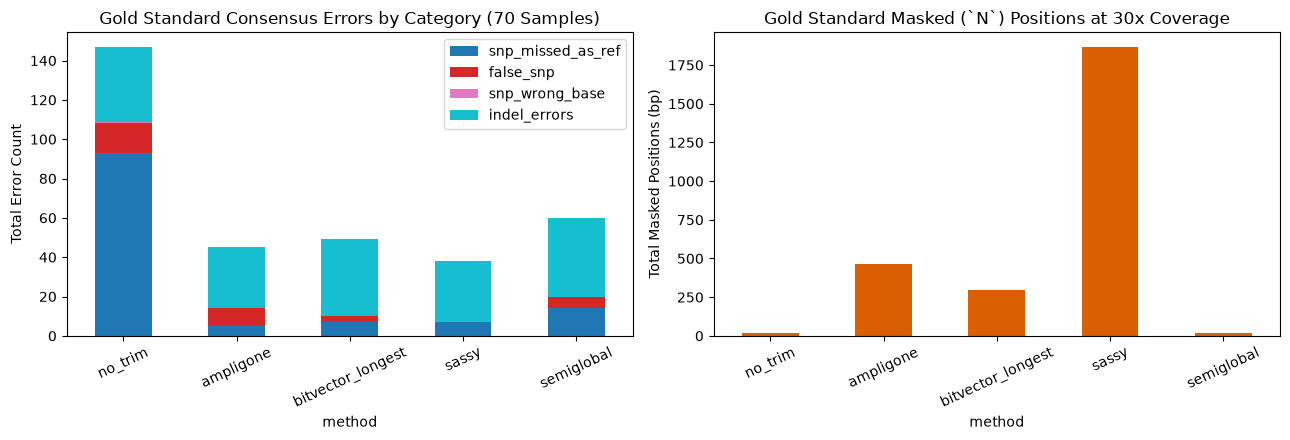


Site-level method disagreements (Gold Standard, 154 positions where methods differ):


no_trim       ampligone bitvector_longest  \
sample      ref_pos                                                        
EQA_2023_01 2831     snp_missed_as_ref             NaN               NaN   
EQA_2023_04 21641                  NaN  false_deletion               NaN   
            21642       false_deletion             NaN    false_deletion   
            29759       false_deletion  false_deletion               NaN   
            29760                  NaN             NaN    false_deletion   
...                                ...             ...               ...   
EQA_2026_07 8834             false_snp             NaN               NaN   
            23221    snp_missed_as_ref             NaN               NaN   
EQA_2026_08 14423                  NaN             NaN    false_deletion   
            14459       false_deletion             NaN               NaN   
            14983       false_deletion             NaN    false_deletion   

                              sassy      semiglobal  n_methods_with_error  
sample      ref_pos                                                        
EQA_2023_01 2831                NaN             NaN                     1  
EQA_2023_04 21641    false_deletion             NaN                     2  
            21642               NaN  false_deletion                     3  
            29759               NaN  false_deletion                     3  
            29760               NaN             NaN                     1  
...                             ...             ...                   ...  
EQA_2026_07 8834                NaN             NaN                     1  
            23221               NaN             NaN                     1  
EQA_2026_08 14423    false_deletion  false_deletion                     3  
            14459               NaN             NaN                     1  
            14983    false_deletion  false_deletion                     4  

[154 rows x 6 columns]

In [33]:
# 3. Read-Level Trim Diagnostics & Error Breakdown Visualization
trim_diag = pd.read_csv(TRIM_DIAG_CSV)
print("Read-Level Trim Diagnostics on EQA_2026_01 and EQA_2026_02:")
display(trim_diag.round(4))

gold_methods = summary_pooled.loc["gold"].loc[list(PRIMER_METHODS)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

err_cols = ["snp_missed_as_ref", "false_snp", "snp_wrong_base", "indel_errors"]
gold_methods[err_cols].plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_title("Gold Standard Consensus Errors by Category (70 Samples)")
axes[0].set_ylabel("Total Error Count")
axes[0].tick_params(axis="x", rotation=25)

gold_methods["masked_positions"].plot(kind="bar", ax=axes[1], color="#d95f02")
axes[1].set_title("Gold Standard Masked (`N`) Positions at 30x Coverage")
axes[1].set_ylabel("Total Masked Positions (bp)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

disagreements = pd.read_csv(DISAGREEMENTS_CSV, index_col=[0, 1])
print(f"\nSite-level method disagreements (Gold Standard, {len(disagreements)} positions where methods differ):")
display(disagreements)